In [20]:
import os 
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from IPython.core.interactiveshell import InteractiveShell  
from ipywidgets import interact  
InteractiveShell.ast_node_interactivity = "all"   # type: ignore
import ipywidgets as widgets
from ipywidgets import interact 

In [21]:
from typing import Any

def show_col_summary(column: Any, frame):
    print(frame[column].describe())

def show_summary(dfs: list[pd.DataFrame], v_dir: Path):
    print(f"Results aggregated over {v_dir.stem} in {v_dir.parent.parent.stem}/{v_dir.parent.stem}")
    for frame in dfs:
        interact(show_col_summary, frame=frame, column=list(frame.columns))
        frame 


In [26]:
def store_summary_metrics(sum, sum_sq, std_header, v_dir, steps, num_metrics):
        # For this/each experiment save this in the parent directory as a summary for runs
        total_mean = sum / num_metrics
        total_var = sum_sq / num_metrics - (np.square(total_mean))
        total_std = np.sqrt(total_var)
        mean_header = list(map(lambda title: f"mean_{title}", std_header))
        total_mean_df = pd.DataFrame(total_mean, columns=mean_header)
        std_header = list(map(lambda title: f"std_{title}", std_header))
        total_std_df = pd.DataFrame(total_std, columns=std_header)

        total_mean_df = pd.concat([steps,total_mean_df], axis=1)
        total_std_df = pd.concat([steps,total_std_df], axis=1)

        summary_save_dir = v_dir.resolve() / "mean.csv"
        total_mean_df.to_csv(summary_save_dir)
        summary_save_dir = v_dir.resolve() / "std_dev.csv"
        total_std_df.to_csv(summary_save_dir)
        # Show these in interactive mode
        print(f"Results aggregated over {v_dir.stem} in {v_dir.parent.parent.stem}/{v_dir.parent.stem}")

        cols = list(total_std_df.columns)
        total_std_df.plot(y=cols[1])
        total_std_df.plot(y=cols[2])

        cols = list(total_mean_df.columns)
        total_mean_df.plot(y=cols[1])
        total_mean_df.plot(y=cols[2])

        plt.show()

Results aggregated over v_0 in adam_class_imbalance_ratios/multirun


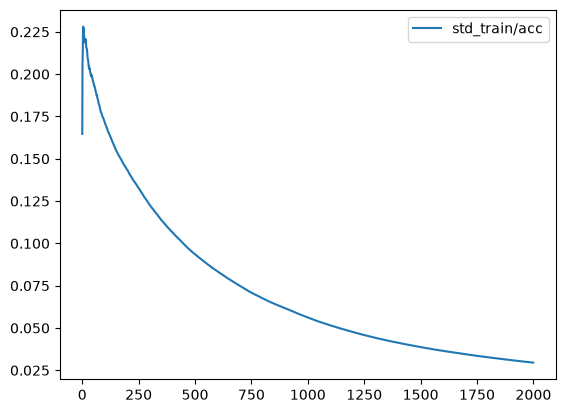

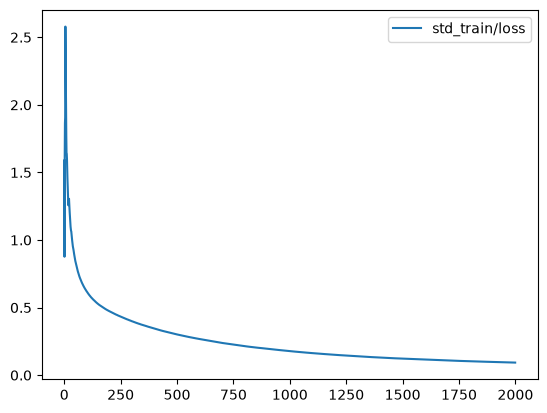

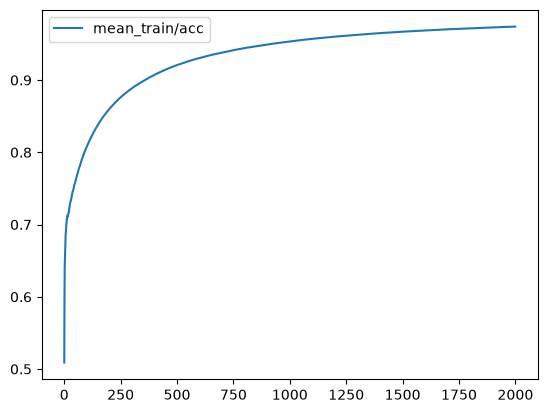

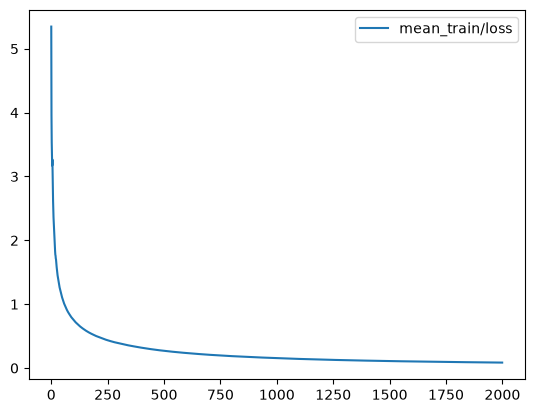

Results aggregated over v_0 in muon_class_imbalance_ratios/multirun


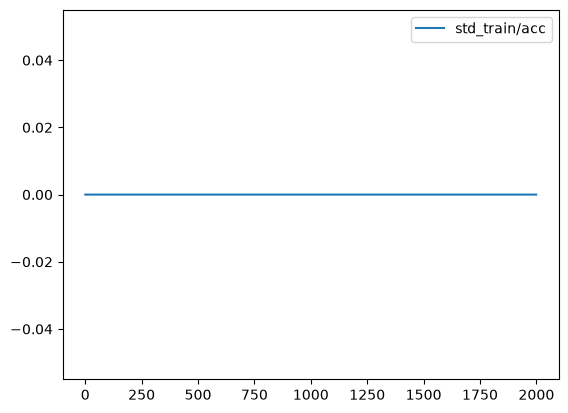

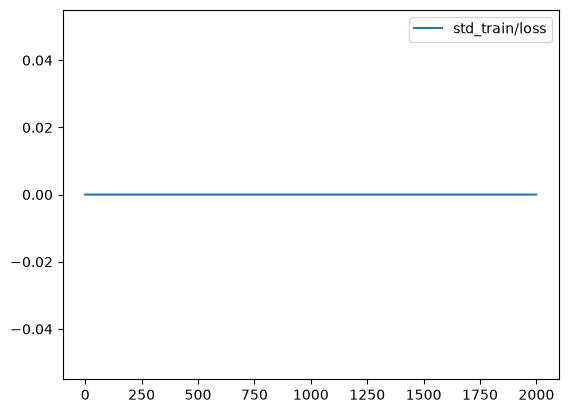

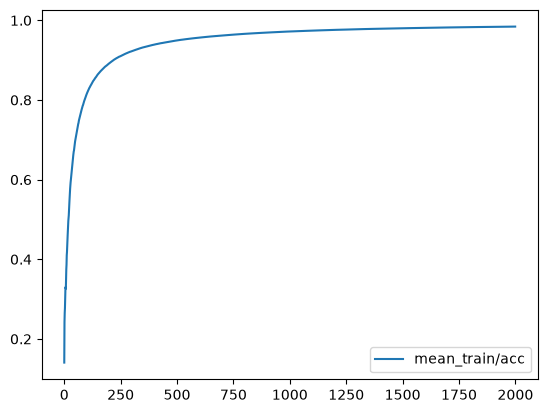

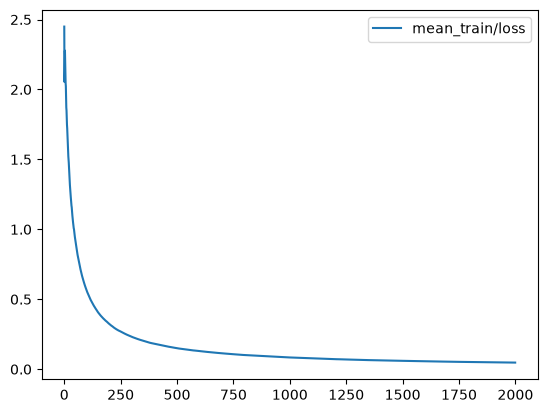

In [ ]:
outputs_dir = Path().resolve().parent / "outputs"

for experim_path in sorted(outputs_dir.iterdir()):
    version_dirs = sorted(experim_path.glob("multijob/v*"))
    for v_dir in version_dirs:
        train_metrics_dirs = sorted(v_dir.rglob("run*/train/metrics.csv", case_sensitive=False))
        num_metrics = len(train_metrics_dirs)

        # Sizes are unknown unless peeking is performed
        sum = np.zeros(0)
        sum_sq = np.zeros(0)
        max = np.zeros(0)
        min = np.zeros(0)
        steps = pd.DataFrame(np.zeros(0))
        header = [""]
        # Save initial path
        enumerated_metrics = enumerate(train_metrics_dirs)

        for i, train_metrics_path in enumerated_metrics:
            data = pd.read_csv(train_metrics_path.resolve(), usecols=[1,2])
            steps = pd.read_csv(train_metrics_path.resolve(), usecols=[0])
            metrics = np.asarray(data.values)
            if i == 0:
                sum = np.zeros_like(metrics)
                sum_sq = np.zeros_like(metrics)
                header = data.columns

            sum = np.sum([sum, metrics], axis=(0))
            sum_sq = np.sum([sum_sq, np.square(metrics)], axis=(0))

        store_summary_metrics(sum, sum_sq, header, v_dir, steps, num_metrics)